# Završni projekat
Analiza potrošnje električne energije u Evropi

In [139]:
#Importovanje svih potrebnih biblioteka

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import seaborn as sns

In [140]:
#Dodavanje kolone Time koja nam olakšava rad sa vremenskim podacima
#Predstavlja broj dana od početka merenja (2015-01-01)

df = pd.read_csv('ember_with_demo.csv')
df["Date"] = pd.to_datetime(df["Date"])
df["Time"] = (df["Date"] - df["Date"].min()).dt.days

df.head()

,Area,ISO 3 code,Date,EU,Category,Subcategory,Variable,Unit,Value,GDP,Time
0,Austria,AUT,2015-01-01,1,Electricity demand,Demand,Demand,TWh,7.58,310082.8,0
1,Austria,AUT,2015-01-01,1,Electricity generation,Aggregate fuel,Clean,%,69.64,310082.8,0
2,Austria,AUT,2015-01-01,1,Electricity generation,Aggregate fuel,Coal,%,4.73,310082.8,0
3,Austria,AUT,2015-01-01,1,Electricity generation,Aggregate fuel,Fossil,%,30.36,310082.8,0
4,Austria,AUT,2015-01-01,1,Electricity generation,Aggregate fuel,"Hydro, bioenergy and other renewables",%,59.09,310082.8,0


# Estimacija parametara raspodela pojedinačnih promenljivih
(matematičko očekivanje,
varijansa, standardna devijacija, medijana, kvartili, kvantili...)

In [141]:
#Priprema zasebnih dataframe-ova jer je originalni datset u tzv. long formatu
demand = df[(df["Variable"]=="Demand") & (df["Unit"]=="TWh")]
total_gen = df[(df["Variable"]=="Total generation") & (df["Unit"]=="TWh")]
clean = df[(df["Variable"]=="Clean") & (df["Unit"]=="%")]
renewables = df[(df["Variable"]=="Renewables") & (df["Unit"]=="%")]
inefficiency = df[(df["Variable"]=="CO2 intensity") & (df["Unit"]=="gCO2e per kWh")]


demand_stats = demand["Value"].describe()
total_gen_stats = total_gen["Value"].describe()
clean_stats = clean["Value"].describe()
renew_stats = renewables["Value"].describe()
inefficiency_stats = inefficiency["Value"].describe()

#demand_stats, total_gen_stats, clean_stats, renew_stats
combined_stats = pd.DataFrame({
    "Potrošnja (TWh)": demand_stats,
    "Proizvodnja (TWh)": total_gen_stats,
    "Čista energija (%)": clean_stats,
    "Obnovljivi izvori (%)": renew_stats,
    "Emisije (g CO2/kWh)": inefficiency_stats
})

combined_stats


,Potrošnja (TWh),Proizvodnja (TWh),Čista energija (%),Obnovljivi izvori (%),Emisije (g CO2/kWh)
count,3802.000000,3802.000000,3802.000000,3802.000000,3802.000000
mean,8.694011,8.722059,57.395692,40.776220,338.104484
std,10.977624,11.482157,25.724419,24.946678,217.536766
min,0.040000,0.020000,0.000000,0.000000,0.000000
25%,1.380000,1.290000,38.392500,20.095000,170.202500
50%,4.325000,4.270000,58.165000,36.505000,314.780000
75%,10.747500,11.390000,76.337500,57.367500,493.282500
max,57.030000,58.690000,100.000000,100.000000,1071.430000


# Estimacija parametara združenih raspodela
Kovarijansa i koeficijent korelacije

$$Cov(\text{X,Y}) = \frac{\text{1}}{\text{n-1}}{​∑(x_i​− \overline x)(y_i​− \overline y​)}$$

In [142]:
kategorije = ["GDP", "EU", "Time"]
for k in kategorije:
  for p in [demand, total_gen, clean, renewables,inefficiency]:
    cov_param = p[[k,"Value"]].cov().iloc[0,1]
    koef_korelacije = cov_param / np.sqrt(p["Value"].var() * p[k].var())
    print(f" {p["Variable"].iloc[0]:18} | {k:6} | Kovarijansa: {cov_param:>12.4f} | Koef. korelacije: {koef_korelacije:>7.4f}")
  print("-"*100)

 Demand             | GDP    | Kovarijansa: 7346802.6994 | Koef. korelacije:  0.9502
 Total generation   | GDP    | Kovarijansa: 7594396.2552 | Koef. korelacije:  0.9390
 Clean              | GDP    | Kovarijansa: 1643029.1957 | Koef. korelacije:  0.0907
 Renewables         | GDP    | Kovarijansa: -604273.7042 | Koef. korelacije: -0.0344
 CO2 intensity      | GDP    | Kovarijansa: -18052966.1582 | Koef. korelacije: -0.1178
----------------------------------------------------------------------------------------------------
 Demand             | EU     | Kovarijansa:      -0.1084 | Koef. korelacije: -0.0246
 Total generation   | EU     | Kovarijansa:      -0.1188 | Koef. korelacije: -0.0258
 Clean              | EU     | Kovarijansa:      -0.3587 | Koef. korelacije: -0.0348
 Renewables         | EU     | Kovarijansa:      -1.1559 | Koef. korelacije: -0.1156
 CO2 intensity      | EU     | Kovarijansa:     -10.4362 | Koef. korelacije: -0.1196
-----------------------------------------------

Analiza korelacija pokazuje snažnu pozitivnu vezu između BDP-a i potrošnje električne energije (r ≈ 0.9502), kao i ukupne proizvodnje (r ≈ 0.939). Ovo je očekivano, jer ekonomski razvijenije zemlje imaju veću industrijsku i poslovnu potrošnju.

Udeo obnovljivih izvora energije i udeo „čiste“ energije pokazuju veoma slabu korelaciju sa BDP-om (r između –0.03 i 0.09), što ukazuje da nivo ekonomske razvijenosti ne utiče značajno na izbor energenata.

Korelacije sa vremenom (date_numeric) ukazuju na jasan trend povećanja udela obnovljivih izvora (r = 0.2341) i smanjenja emisija CO₂ električne energije (r = –0.1818).

Korelacije sa binarnim indikatorom EU članstva su male (|r| < 0.12), što pokazuje da postoje značajne razlike među državama članicama EU.

# Estimacija uslovnih i bezuslovnih verovatnoća

Bezuslovna verovatnoća Emisije CO²

$$P(\text{Emisije CO²}) = \frac{\text{Broj slučajeva CO² u opsegu}}{\text{Ukupan broj slučajeva}}$$

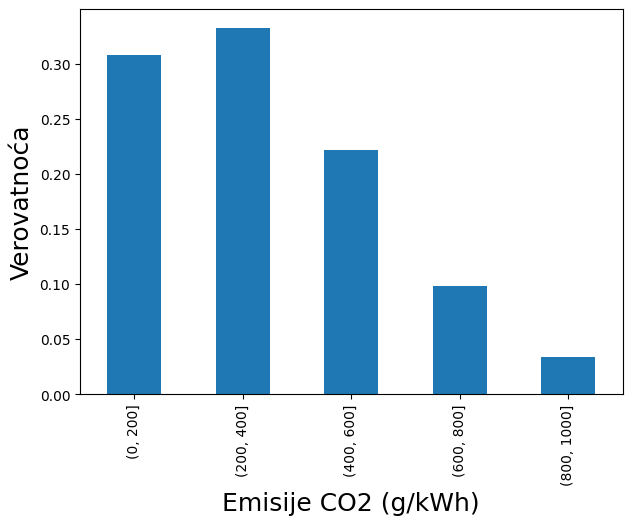

In [143]:
granice = [0, 200, 400, 600, 800, 1000]

P_A = pd.cut(inefficiency["Value"], bins=granice)
P_A = P_A.value_counts(sort=False) / inefficiency.shape[0]

P_A.plot(kind='bar', figsize=(7,5))
plt.xlabel("Emisije CO2 (g/kWh)", fontsize=18)
plt.ylabel("Verovatnoća", fontsize=18)
plt.show()

Uslovna verovatnoća

Verovatnoća da emisije CO2 budu niska pod uslovom da je visok procenat obnovljivih izvora energije

$$P(\text{niske emisije}\ |\ \text{obnovljivi izvori})= \frac{\text{Broj slucajeva sa niskim emisijama i visokim stepenom obnovljivosti}}{\text{Ukupan broj slucajeva sa visokim stepenom obnovljivosti}}$$

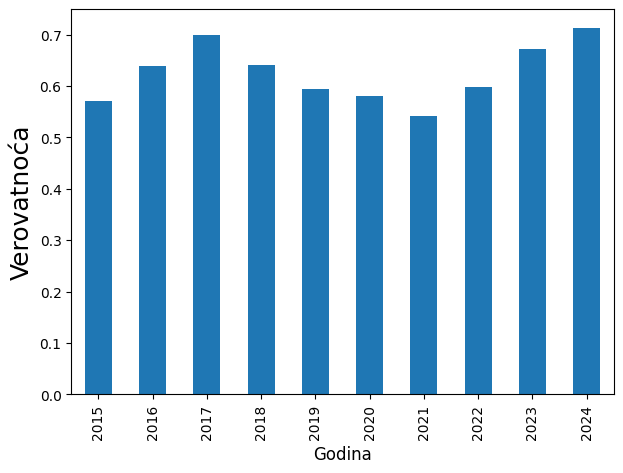

In [144]:
df_uslovna = pd.merge(
    renewables[["ISO 3 code", "Date", "Value"]].rename(columns={"Value": "renewables"}),
    inefficiency[["ISO 3 code", "Date", "Value"]].rename(columns={"Value": "inefficiency"}),
    on=["ISO 3 code", "Date"],
    how="inner"
)

df_uslovna["year"] = pd.to_datetime(df_uslovna["Date"]).dt.year

granica_renew = df_uslovna["renewables"].quantile(0.75)
granica_co2 = df_uslovna["inefficiency"].quantile(0.25)


df_uslovna["A"] = df_uslovna["inefficiency"] < granica_co2 # A - niske emisije CO2
df_uslovna["B"] = df_uslovna["renewables"] > granica_renew # B - Često se koriste obnovljivi izvori energije

# Izračunamo uslovnu verovatnoću P(A | B)
P_godine = (
    df_uslovna[df_uslovna["B"]]
    .groupby("year")["A"]
    .mean()
)

P_godine.plot(kind='bar', figsize=(7,5))
plt.xlabel("Godina", fontsize=12)
plt.ylabel("Verovatnoća", fontsize=18)
plt.show()


# Estimacija intervala poverenja

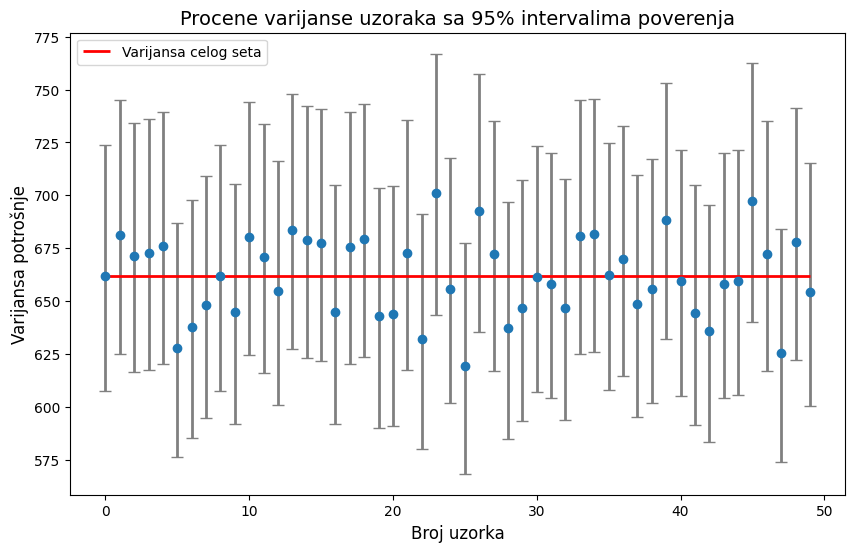

In [151]:
velicina_uzorka = 1000
broj_estimacija_varijansi = 50
alpha = 0.05

estimatori_varijanse = []
intervali_poverenja = []

for i in range(broj_estimacija_varijansi):
    uzorak = clean['Value'].sample(velicina_uzorka)
    var = uzorak.var(ddof=1)
    estimatori_varijanse.append(var)
    # Određivanje granica intervala poverenja
    chi2_lower = stats.chi2.ppf(alpha/2, velicina_uzorka - 1)
    chi2_upper = stats.chi2.ppf(1 - alpha/2, velicina_uzorka - 1)
    donja = (velicina_uzorka - 1) * var / chi2_upper
    gornja = (velicina_uzorka - 1) * var / chi2_lower
    intervali_poverenja.append((donja, gornja))

estimatori_varijanse = np.array(estimatori_varijanse)
intervali_poverenja = np.array(intervali_poverenja)

# Iscrtavanje
plt.figure(figsize=(10,6))
plt.errorbar(
    x=np.arange(broj_estimacija_varijansi),
    y=estimatori_varijanse,
    yerr=[estimatori_varijanse - intervali_poverenja[:,0],
          intervali_poverenja[:,1] - estimatori_varijanse],
    fmt='o', ecolor='gray', elinewidth=2, capsize=4
)

plt.hlines(
    y=clean['Value'].var(ddof=1),
    xmin=0, xmax=broj_estimacija_varijansi-1,
    color='red', linewidth=2.0, label='Varijansa celog seta'
)

plt.title("Procene varijanse uzoraka sa 95% intervalima poverenja", fontsize=14)
plt.xlabel("Broj uzorka", fontsize=12)
plt.ylabel("Varijansa potrošnje", fontsize=12)
plt.legend()
plt.show()

# Regresija


**Linearna regresija**

---


Potrošnja električne energije ~ BDP


                            OLS Regression Results                            
Dep. Variable:                  Value   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.903
Method:                 Least Squares   F-statistic:                 3.529e+04
Date:                Mon, 24 Nov 2025   Prob (F-statistic):               0.00
Time:                        14:24:12   Log-Likelihood:                -10072.
No. Observations:                3802   AIC:                         2.015e+04
Df Residuals:                    3800   BIC:                         2.016e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.6733      0.067     25.004      0.0

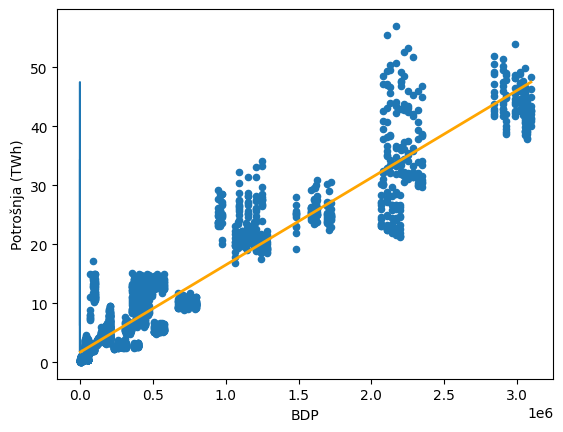

In [146]:
Rez1 = smf.ols('Value ~ GDP', demand).fit()
demand.plot('GDP', 'Value', kind='scatter')
plt.plot(demand.Value, Rez1.fittedvalues)

#Sortiranje radi prikaza linije
val_1_sorted = demand.assign(fitted = Rez1.fittedvalues).sort_values("GDP")
plt.plot(val_1_sorted["GDP"], val_1_sorted["fitted"], color='orange', linewidth=2)

#Iscrtavanje
plt.xlabel("BDP")
plt.ylabel("Potrošnja (TWh)")

print(Rez1.summary())

                            OLS Regression Results                            
Dep. Variable:                  Value   R-squared:                       0.055
Model:                            OLS   Adj. R-squared:                  0.055
Method:                 Least Squares   F-statistic:                     220.3
Date:                Mon, 24 Nov 2025   Prob (F-statistic):           1.73e-48
Time:                        14:24:12   Log-Likelihood:                -17517.
No. Observations:                3802   AIC:                         3.504e+04
Df Residuals:                    3800   BIC:                         3.505e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     29.9062      0.831     35.974      0.0

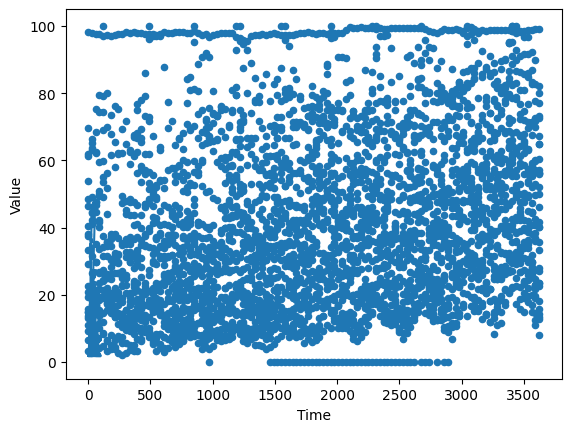

In [147]:
#Nedovoljna korelacija, ostavljeno kao primer (koef. korelacije r=0.2341)

Rez2 = smf.ols('Value ~ Time', renewables).fit()
renewables.plot('Time', 'Value', kind='scatter')
plt.plot(renewables.Value, Rez1.fittedvalues)

val_2_sorted = renewables.assign(fitted = Rez1.fittedvalues).sort_values("Time")
plt.plot(val_2_sorted["Time"], val_2_sorted["fitted"], color='orange', linewidth=2)

print(Rez2.summary())

**Polinomska regresija**

Zaključujemo da je najbolji izbor kvadratni model (R²=0.907)
Iz ovog modela takođe zaključujemo da odnos BDP-a i potrošnje el. energije je povezan, ali nije strogo linearan (porast BDP-a ima sve manji efekat).

In [148]:
Rez1 = smf.ols('Value ~ GDP', demand).fit()
Rez2 = smf.ols('Value ~ GDP + I(GDP**2)', demand).fit()
Rez3 = smf.ols('Value ~ GDP + I(GDP**2) + I(GDP**3)', demand).fit()

print("-"*32, "Linearna regresija","-"*32)
print(Rez1.summary())
print("\n","-"*32,"Polinomska regresija (kvadratna)","-"*32)
print(Rez2.summary())
print("\n","-"*32,"Polinomska regresija (kubna)","-"*32)
print(Rez3.summary())

-------------------------------- Linearna regresija --------------------------------
                            OLS Regression Results                            
Dep. Variable:                  Value   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.903
Method:                 Least Squares   F-statistic:                 3.529e+04
Date:                Mon, 24 Nov 2025   Prob (F-statistic):               0.00
Time:                        14:24:12   Log-Likelihood:                -10072.
No. Observations:                3802   AIC:                         2.015e+04
Df Residuals:                    3800   BIC:                         2.016e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------

**Višestruka regresija**

Posmatramo BDP kao zavisnu promenjivu. Kao parametre uzimamo potrošnju el. energije, procenat obnovljivosti, količina emisija CO²

In [149]:
merged = (
    demand[["ISO 3 code", "Time", "Value", "GDP"]].rename(columns={"Value": "demand"})
    .merge(renewables[["ISO 3 code", "Time", "Value"]].rename(columns={"Value": "renewables"}),
           on=["ISO 3 code", "Time"], how="inner")
    .merge(inefficiency[["ISO 3 code", "Time", "Value"]].rename(columns={"Value": "co2_intensity"}),
           on=["ISO 3 code", "Time"], how="inner")
)
Rez3 = smf.ols(
    formula="GDP ~ demand + renewables + co2_intensity",
    data=merged
).fit()

print(Rez3.summary())

                            OLS Regression Results                            
Dep. Variable:                    GDP   R-squared:                       0.904
Model:                            OLS   Adj. R-squared:                  0.904
Method:                 Least Squares   F-statistic:                 1.192e+04
Date:                Mon, 24 Nov 2025   Prob (F-statistic):               0.00
Time:                        14:24:13   Log-Likelihood:                -52133.
No. Observations:                3802   AIC:                         1.043e+05
Df Residuals:                    3798   BIC:                         1.043e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -9.458e+04   1.43e+04     -6.606